# Step 4: Baselines and LambdaMART

**BT4222 Final Project, Group 13, JDSearch**

Step 4 sets the bar every later model must beat. It evaluates five reference rankers on the test slates, from the trivial (random order, popularity) to the strongest classical one (LambdaMART on the 26 features), and fits the SVD collaborative-filtering baseline with a protocol that is fair to held-out users.

## How to read this notebook

Every code cell is cut verbatim from `src/step4_baselines_lgbm.py`, so the notebook and the script cannot drift apart
(`tests/test_notebooks.py` checks it). Each cell is preceded by a short explanation of what it does and
why, and the table below links every section to the function that implements it and to the file it
produces, so any number in the report can be traced back to a cell.

* **Part A** rebuilds the step. It needs the inputs listed below.
* **Part B** reads the measured outputs of the corrected run (`artifacts/corrected`) and re-checks them.
  It needs no raw data, so it always runs and its outputs are saved in this copy of the notebook.

| Section | What it does | Code in `src/step4_baselines_lgbm.py` | Writes |
|---|---|---|---|
| A.1 | LambdaMART settings and trainer | `LGB_PARAMS`, `fit_ranker` | - |
| A.2 | SVD with fold-in for held-out users | `fold_in_svd` | - |
| A.3 | Load features, define the scoring helper | `main()` | - |
| A.4 | Random, popularity and content-only baselines | `main()` | - |
| A.5 | SVD baseline | `main()` | `svd.joblib` |
| A.6 | LambdaMART on the features | `main()` | - |
| A.7 | Train / validation scores, importance, saved predictions | `main()` | `lgb_model.txt`, `test_pred_lgb.parquet`, `lgb_feature_importance.csv`, `results_baselines_lgb.json`, `baseline_protocol.json` |
| B.1 | Baseline table of the corrected run | - | - |
| B.2 | Recompute the table from the saved predictions | - | - |
| B.3 | Which features does LambdaMART use? | - | - |

**Inputs.** `features.parquet`, `history.parquet`, `sessions.parquet` from Steps 2 and 3.

**Outputs.** Baseline metrics, the LambdaMART booster and the test-set predictions that Steps 5, 6 and 7 read.

## How rankers are scored (`src/eval_utils.py`)

Every model in this project is scored by the same code, so the numbers are comparable.

* **Unit of evaluation: one query.** Metrics are computed per query over its **whole slate** and then
  averaged (macro average). Queries with no positive label cannot be ranked well or badly, so they are
  skipped (35 of 3,000 test queries); the rest are the "positive queries".
* **Gains.** Labels 0, 1, 2, 3 (none, click, cart, purchase) get gains 0, 1, 3, 7 (`2^label - 1`), so a purchase in
  the top 10 is worth more than a click.
* **Metrics.** NDCG@10 (main), MRR@200, P@1 (is the first item a positive?) and HR@10 (any positive in the top 10).
* **Order-invariant ties.** Equal scores are broken by a hash of (session, product id), never by the position in
  the file. This matters: in the raw data the first candidate is a positive in 98.8% of the slates, so a
  scorer that only returns "keep the file order" would look excellent.

## 0. Environment setup

The first cell finds the project and puts `src/` on `sys.path`, so `config`, `data_utils`
and `eval_utils` can be imported exactly as the scripts do.

* **In Colab** it clones the repository (branch set in `BRANCH`). Set `MOUNT_DRIVE = True` if the
  raw files live on Google Drive: raw paths and the output folder then point to Drive, so the
  outputs of one step survive until the next notebook.
* **Locally** it looks for `Final Project/` next to the notebook.
* All paths come from environment variables read by `src/config.py`:
  `JD_USER_TXT`, `JD_PRODUCT_TXT` (raw files), `JD_RUN_DIR` (where outputs are written, default
  `artifacts/corrected`), `JD_SEED` (default 42).

In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "main"   # final submission branch
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("in Colab    :", IN_COLAB)
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

in Colab    : False
project root: Final Project
run dir     : <default: artifacts/corrected>


## 1. Imports and shared helpers

`evaluate` scores a data frame of predictions (one score column) with the protocol above.
`tie_keys` produces the deterministic tie-breaking hashes (also used to make the random baseline
reproducible). `lightgbm_metric` is the same NDCG@10 as a LightGBM early-stopping callback, so the
model selects its number of trees on exactly the metric we report.

In [2]:
import json, time
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD

from config import OUT, RES, SEED, THREADS, feature_columns, prepare, save_json
from eval_utils import evaluate, tie_keys, lightgbm_metric

%matplotlib inline
prepare()

### 1.1 What can run here? (the `RUN_STEP` switch)

Part A rebuilds this step and Part B reads the measured outputs, so the switch below decides whether
Part A runs.

* Part A runs only if its **inputs exist**, and it will not overwrite the committed evidence in
  `artifacts/corrected` unless you explicitly allow it (`ALLOW_OVERWRITE`). In Colab the clone is
  disposable, so overwriting is allowed by default; locally, point `JD_RUN_DIR` at a new folder.
* If Part A is skipped, nothing fails: **Part B always runs** and shows the saved results.

In [3]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = all((OUT / f"{n}.parquet").exists() for n in ["features", "history", "sessions"])
RUN_STEP = HAS_INPUTS and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", RES)
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    why = ("required inputs not found: features, history, sessions parquet files (run Steps 2 and 3 first)" if not HAS_INPUTS else
           "outputs would overwrite artifacts/corrected; set JD_RUN_DIR to a new folder or ALLOW_OVERWRITE = True")
    print("Part A is skipped here (" + why + ").")
    print("Part B below shows the measured outputs saved in", RES)

inputs found    : False
outputs go to   : Final Project/artifacts/corrected
RUN_STEP        : False
Part A is skipped here (required inputs not found: features, history, sessions parquet files (run Steps 2 and 3 first)).
Part B below shows the measured outputs saved in Final Project/artifacts/corrected


# Part A: Fit and score the baselines

### A.1 LambdaMART: settings and trainer

LambdaMART is gradient-boosted trees trained to optimise a ranking loss (`objective='lambdarank'`) with
the gains `[0, 1, 3, 7]`. `fit_ranker` trains on the training slates (sorted by session and product id so
the result does not depend on file order), watches the validation NDCG@10 and stops after 50 rounds
without improvement (at most 600 trees). `deterministic=True` and a fixed seed make the run repeatable.

In [4]:
LGB_PARAMS = dict(objective='lambdarank', metric='None', learning_rate=.05,
    num_leaves=63, min_data_in_leaf=200, feature_fraction=.9,
    bagging_fraction=.9, bagging_freq=1, label_gain=[0,1,3,7],
    verbosity=-1, seed=SEED, num_threads=THREADS, deterministic=True, force_col_wise=True)

def fit_ranker(feat, columns):
    tr = feat[feat.split=='train'].sort_values(['session_id','cand_wid']).reset_index(drop=True)
    va = feat[feat.split=='val'].sort_values(['session_id','cand_wid']).reset_index(drop=True)
    groups = lambda d:d.groupby('session_id',sort=False).size().to_numpy()
    train = lgb.Dataset(tr[columns], label=tr.label, group=groups(tr))
    valid = lgb.Dataset(va[columns], label=va.label, group=groups(va), reference=train)
    return lgb.train(LGB_PARAMS,train,num_boost_round=600,valid_sets=[valid],
        feval=lightgbm_metric(va),
        callbacks=[lgb.early_stopping(50,verbose=False),lgb.log_evaluation(100)])

### A.2 SVD collaborative filtering with fold-in

Classic matrix factorisation needs a latent vector per user, but test users have **no training row**.
The draft gave them an untrained user-id embedding, which is why its neural CF scored like random (0.086):
that was a protocol bug, not a property of CF. The fair version used here:

1. fit the item factors on a user-by-item matrix of **training** histories only;
2. represent any other session by projecting its own preceding history onto those fixed factors
   ("fold-in");
3. score a candidate as the dot product of the session vector and the item vector (0 for items the
   training histories never contained).

In [5]:
def fold_in_svd(hist, train_ids, n_sessions, dimensions=64):
    """Fit shared item factors on training histories, transform other histories only."""
    train_hist = hist[hist.session_id.isin(train_ids)]
    items = {w:i for i,w in enumerate(sorted(train_hist.wid.unique()))}
    mapped = hist.wid.map(items); keep = mapped.notna()
    matrix = csr_matrix((np.ones(int(keep.sum()),dtype=np.float32),
        (hist.loc[keep,'session_id'].to_numpy(),mapped[keep].astype(int).to_numpy())),
        shape=(n_sessions,len(items)),dtype=np.float32)
    k = min(dimensions,len(train_ids)-1,len(items)-1)
    if k < 1:
        raise ValueError('Insufficient training users/items for SVD')
    svd = TruncatedSVD(n_components=k,random_state=SEED)
    svd.fit(matrix[sorted(train_ids)])
    return items,svd,svd.transform(matrix)

### A.3 Load the features and define the scoring helper

`report` evaluates one score column on the test slates and records the metrics and the number of
evaluable queries, so every baseline goes through the same protocol.

In [6]:
start = time.time()

In [7]:
if RUN_STEP:
    feat=pd.read_parquet(OUT/'features.parquet')
    hist=pd.read_parquet(OUT/'history.parquet')
    sess=pd.read_parquet(OUT/'sessions.parquet')
    test=feat[feat.split=='test'].copy()
    results={}; detail={}
    def report(name,df,col):
        m,n=evaluate(df,col); results[name]=m
        detail[name]={'queries_with_positive':n,'all_queries':int(df.session_id.nunique())}
        print(name,m,flush=True)

### A.4 Reference baselines

* **Random**: a pseudo-random score from the tie hash (reproducible, independent of file order).
* **Popularity**: rank by `pop_wid`, how often the item appears in training histories.
* **Content / relevance only**: query-to-product overlap (`ov_name + ov_cat + 0.5 * ov_brand + jacc_name`),
  with no user information at all.

In [8]:
if RUN_STEP:
    test['random_score']=tie_keys(test,SEED+1).astype(float)/np.iinfo(np.uint64).max
    test['content_score']=test.ov_name+test.ov_cat+.5*test.ov_brand+test.jacc_name
    report('Random',test,'random_score')
    report('Popularity',test,'pop_wid')
    report('Content/Relevance-only',test,'content_score')

### A.5 SVD baseline

Fit the factors on training histories, fold in every session, and score the test candidates in blocks of
20,000 rows so memory stays bounded. `svd_train_history_item_coverage` (saved later in the protocol file)
is the share of test candidates that the training histories contain.

In [9]:
if RUN_STEP:
    train_ids=set(sess.loc[sess.split=='train','session_id'])
    items,svd,user_factors=fold_in_svd(hist,train_ids,int(sess.session_id.max())+1)
    factors=svd.components_.T
    mapped=test.cand_wid.map(items)
    scores=np.zeros(len(test),dtype=np.float32); warm=mapped.notna().to_numpy()
    ids=mapped.fillna(0).astype(int).to_numpy()
    # Bounded temporary arrays avoid duplicating a whole candidate x factor matrix.
    sids=test.session_id.to_numpy()
    for a in range(0,len(test),20000):
        b=min(a+20000,len(test)); ok=warm[a:b]
        block=np.zeros(b-a,dtype=np.float32)
        block[ok]=np.einsum('ij,ij->i',user_factors[sids[a:b][ok]],factors[ids[a:b][ok]])
        scores[a:b]=block
    test['svd_score']=scores
    report('SVD(train-only fold-in)',test,'svd_score')
    joblib.dump({'svd':svd,'item_ids':items},OUT/'svd.joblib',compress=3)

### A.6 LambdaMART on the 26 features

The strongest classical ranker: all Step 3 features, trees selected on validation NDCG@10.

In [10]:
if RUN_STEP:
    columns=feature_columns(feat)
    booster=fit_ranker(feat,columns)
    test['lgb_score']=booster.predict(test[columns])
    report('LambdaMART(features)',test,'lgb_score')

### A.7 Train and validation scores, importance and saved outputs

Scoring the training and validation slates as well shows how much the booster overfits (train NDCG@10 is
much higher than test). The booster, the feature importances, the test predictions of every baseline
and the protocol (query counts, tree count, parameters) are saved for Steps 5 to 7.

In [11]:
if RUN_STEP:
    for split in ['train','val']:
        frame=feat[feat.split==split].copy()
        frame['lgb_score']=booster.predict(frame[columns])
        report(f'LambdaMART(features)_{split}',frame,'lgb_score')
        report(f'Popularity_{split}',frame,'pop_wid')
    pd.DataFrame({'feature':columns,'gain':booster.feature_importance('gain')}).sort_values(
        'gain',ascending=False).to_csv(RES/'lgb_feature_importance.csv',index=False)
    booster.save_model(str(OUT/'lgb_model.txt'))
    test[['session_id','cand_wid','label','lgb_score','svd_score','random_score',
          'content_score','pop_wid']].to_parquet(OUT/'test_pred_lgb.parquet',index=False)
    save_json(OUT/'lgb_preprocessing.json',{'feature_columns':columns,'schema_version':2})
    save_json(RES/'results_baselines_lgb.json',results)
    save_json(RES/'baseline_protocol.json',dict(query_counts=detail,seed=SEED,
        svd_train_history_item_coverage=float(warm.mean()),lgb_parameters=LGB_PARAMS,
        best_iteration=booster.best_iteration,
        evaluation='macro full-slate metrics, positive queries only, deterministic ID tie keys',
        svd='train-history item factors; held-out preceding history folded into fixed factors'))
    print(f'Step 4 complete ({time.time()-start:.0f}s)',flush=True)

# Part B: Measured outputs of the corrected run

### B.1 Baseline table

Test slates of the 20,000-user sample (3,000 test queries, 2,965 with a positive). The `_train` and
`_val` rows are the same model scored on its own training slates and on validation.

In [12]:
res = json.loads((RES / "results_baselines_lgb.json").read_text(encoding="utf-8"))
table = pd.DataFrame(res).T[["NDCG@10", "MRR@200", "P@1", "HR@10"]]
display(table.round(4))
protocol = json.loads((RES / "baseline_protocol.json").read_text(encoding="utf-8"))
print("LambdaMART trees (best iteration):", protocol["best_iteration"])
print("share of test candidates with an SVD item factor:", round(protocol["svd_train_history_item_coverage"], 4))
print("evaluation:", protocol["evaluation"])

,NDCG@10,MRR@200,P@1,HR@10
Random,0.0829,0.1034,0.0314,0.2277
Popularity,0.3045,0.3113,0.1865,0.5771
Content/Relevance-only,0.0951,0.1088,0.0354,0.2442
SVD(train-only fold-in),0.2759,0.2819,0.1592,0.5356
LambdaMART(features),0.3630,0.3669,0.2297,0.6516
LambdaMART(features)_train,0.4562,0.4661,0.3297,0.7565
Popularity_train,0.3190,0.3175,0.1811,0.6091
LambdaMART(features)_val,0.3558,0.3600,0.2295,0.6343
Popularity_val,0.3065,0.3044,0.1766,0.5827


LambdaMART trees (best iteration): 237
share of test candidates with an SVD item factor: 0.1967
evaluation: macro full-slate metrics, positive queries only, deterministic ID tie keys


**Reading.** Popularity (0.305) is already a strong reference and beats the SVD collaborative filter
(0.276): JDSearch candidates are mostly items that no training history contains (only about 20% of the
test candidates have an SVD item factor), so latent item factors cover little. LambdaMART on the features reaches 0.363. Its training score (0.456) is far above
validation (0.356) and test (0.363), so some overfitting exists, but validation and test agree.

### B.2 Recompute the table from the saved predictions

`test_pred_lgb.parquet` holds every baseline's test score. Re-scoring it with `evaluate` must give the
numbers above to the last decimal; this is the traceability check between the file Step 6 and Step 7
read and the table the report quotes.

In [13]:
pred = pd.read_parquet(OUT / "test_pred_lgb.parquet")
columns_by_name = {"Random": "random_score", "Popularity": "pop_wid",
                   "Content/Relevance-only": "content_score",
                   "SVD(train-only fold-in)": "svd_score", "LambdaMART(features)": "lgb_score"}
rows = []
for name, col in columns_by_name.items():
    m, n = evaluate(pred, col)
    rows.append(dict(model=name, recomputed=m["NDCG@10"], saved=res[name]["NDCG@10"],
                     abs_diff=abs(m["NDCG@10"] - res[name]["NDCG@10"]), positive_queries=n))
check = pd.DataFrame(rows).set_index("model")
display(check.round(6))
assert check.abs_diff.max() < 1e-9, "saved predictions do not reproduce the saved metrics"
print("max absolute difference:", check.abs_diff.max())

,recomputed,saved,abs_diff,positive_queries
model,,,,
Random,0.082879,0.082879,0.0,2965
Popularity,0.304526,0.304526,0.0,2965
Content/Relevance-only,0.095082,0.095082,0.0,2965
SVD(train-only fold-in),0.275890,0.275890,0.0,2965
LambdaMART(features),0.363006,0.363006,0.0,2965


max absolute difference: 0.0


### B.3 Which features does LambdaMART use?

Total split gain per feature. Popularity of the item dominates, followed by whether the user has seen
the item before; the temporal horizon features rank lower individually, but Step 6 shows that as a
bundle they are worth +0.024 NDCG@10.

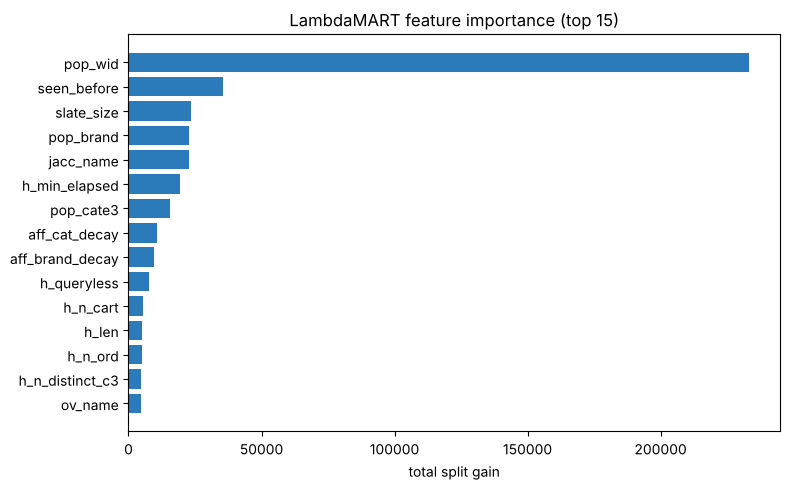

In [14]:
importance = pd.read_csv(RES / "lgb_feature_importance.csv")
top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.feature, top.gain, color="#2b7bba")
ax.set(xlabel="total split gain", title="LambdaMART feature importance (top 15)")
plt.tight_layout()
plt.show()

# Summary

* Five reference rankers share one scoring protocol. Popularity 0.305, SVD with fold-in 0.276,
  LambdaMART 0.363 NDCG@10 on the test slates.
* The collaborative-filtering baseline is real but weak because most candidates are unseen items; the
  earlier "CF collapses to random" claim was a protocol bug and is retracted.
* B.2 proves that the saved predictions reproduce the reported table.

**Hand-off:** `lgb_model.txt` and `test_pred_lgb.parquet` go to Steps 6 and 7; `features.parquet` to Step 5.